# 09 - Word-level analysis: where inside a participant does extraction fail?

The strict span metric scores a participant as right or wrong and stops there. The
relaxed, word-level evaluation (`src/evaluate.py::macro_averaged_f1_score`) goes one
level down: it aligns each predicted span against its best-matching annotation with
`difflib.ndiff` and books every word as

| verdict | meaning |
| --- | --- |
| `tp` | word present in both the prediction and the annotation |
| `fp` | word the model added, absent from the annotation |
| `fn` | annotation word the model did not produce |

This notebook asks **which word of a participant goes wrong**. A two-word participant
such as *"o ministro"* can fail at its first word (the article dropped or added) or at
its second (the head noun missed). Those are different failures, and the aggregate F1-r
hides the difference.

Two main sections, scored by the same code against the same annotations:

1. **Document-level test results** - `results/test/{language}/`, each model at its
   selected best configuration.
2. **Sentence-level results** - `results/sentence_level/ext/{language}/`, `qwen3_14b`
   at *T*=0.3, both prompt conditions.

### Recovering the word position

The stored CSV keeps each word's verdict but not its position, so the notebook replays
the same `ndiff` walk over `complete_prediction` vs `matched_annotation` and adds a slot
counter. The replay is asserted to reproduce the pipeline's own `tp`/`fp`/`fn` verdict
for every row, so nothing here is a re-implementation of the metric - only an
annotation of it.

`tp` and `fn` words *are* annotation words and take their own 1-based index. `fp` words
are not in the annotation, so they are anchored to the slot they align against - the
next annotation slot. `ndiff` emits a substitution as `- prediction` immediately
followed by `+ annotation`, so a word swapped for another lands on the slot it was
swapped for; a trailing `fp` (prediction longer than the annotation) clamps to the last
slot. **Read the `fp` share of a slot as "extra words the model attached at this point
of the participant", not as a property of the annotation word itself.**

In [44]:
import sys

sys.path.insert(0, ".")        # _common
sys.path.insert(0, "../..")    # project root: src/, experiments/

import ast
import contextlib
import difflib
import io
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import _common as c
from experiments.constants import (
    WORD_CATEGORIES_EN,
    WORD_CATEGORIES_PT,
    word_to_category,
)
from src.reader import read_lusa, read_lusa_en
from src.utils import tokenize as _tokenize

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)

# Okabe-Ito, consistent with _common.py. One colour per word-level verdict,
# reused by every figure below so a verdict keeps its identity across the notebook.
OUTCOME_ORDER = ["tp", "fn", "fp"]
OUTCOME_LABELS = {
    "tp": "TP - word matched",
    "fn": "FN - annotation word missed",
    "fp": "FP - word added by the model",
}
OUTCOME_COLORS = {"tp": "#009E73", "fn": "#D55E00", "fp": "#0072B2"}

# Lexical categories get a FIXED colour, not one assigned by their rank within a
# given figure -- otherwise "Places & Facilities" would be pink in one figure and
# "Organizations & Institutions" pink in the next, and the figures could not be read
# against each other. The seven kept here are the categories that carry the errors;
# the remaining constants.py labels (Person Names, Numbers & Quantities, Objects &
# Substances) fold into "Other" so the palette never has to stretch past eight hues.
CATEGORY_COLORS = {
    "Articles & Determiners": "#0072B2",
    "Prepositions & Connectives": "#D55E00",
    "Generic Person Nouns": "#009E73",
    "Places & Facilities": "#CC79A7",
    "Organizations & Institutions": "#E69F00",
    "Other Content Words": "#56B4E9",
    "Names & other content": "#666666",
    "Other": "#BBBBBB",
}
CATEGORY_ORDER = list(CATEGORY_COLORS)

SURFACE = "#FFFFFF"   # drawn between stacked segments to keep them separable
ORDINALS = {1: "1st word", 2: "2nd word", 3: "3rd word", 4: "4th word", 5: "5th word"}
SHORT_LANGUAGE = {"portuguese": "PT", "english": "EN"}

## Helpers

`tokenize` is imported from the pipeline rather than reimplemented, so a "word" here is
exactly what the evaluator counted. It prints on every call and is called on the same
strings repeatedly, hence the silencing wrapper and the cache.

In [45]:
@lru_cache(maxsize=None)
def tokenize(text: str) -> tuple:
    """`src.utils.tokenize`, silenced (it prints on every call) and cached."""
    if not isinstance(text, str) or not text:
        return ()
    with contextlib.redirect_stdout(io.StringIO()):
        return tuple(_tokenize(text))


WORD_CATEGORIES = {"portuguese": WORD_CATEGORIES_PT, "english": WORD_CATEGORIES_EN}
UNLISTED = "Names & other content"


def categorize(token: str, language: str) -> str:
    """Re-derives a word's lexical category from the *current* constants.py.

    The `word_category` column stored in the CSVs was written by an earlier
    vocabulary -- Portuguese labels on the PT side ("Artigos"), a different English
    set on the EN side ("Articles") -- so as stored the two languages cannot be put
    on one axis. `constants.py` now maps both onto a single English label set;
    re-deriving here makes the PT and EN halves of a figure mean the same thing
    without re-running evaluation over every result tree. The stored column is kept
    as `word_category` for reference.
    """
    label = word_to_category(token, WORD_CATEGORIES[language])
    return UNLISTED if label == "Nao definido" else label

In [46]:
def _replay_alignment(pred_repr: str, ann_text: str) -> dict:
    """Recovers each word's slot in the annotation by replaying the scorer's diff.

    Mirrors `src/evaluate.py::macro_averaged_f1_score`: walk
    `difflib.ndiff(prediction_tokens, annotation_tokens)`, emit one record per word
    ('  ' -> tp, '- ' -> fp, '+ ' -> fn), and skip a token already seen for this
    prediction. The only addition is `slot`, the 1-based index into the annotation.

    Returns {token: (verdict, slot, annotation_length)}, deduplicated exactly as the
    pipeline does so it joins one-to-one onto the stored rows.
    """
    try:
        pred_tokens = list(ast.literal_eval(pred_repr))
    except (ValueError, SyntaxError):
        return {}
    ann_tokens = list(tokenize(ann_text))
    n_ann = len(ann_tokens)

    seen, recovered, slot = set(), {}, 0
    for line in difflib.ndiff(pred_tokens, ann_tokens):
        tag, token = line[:2], line[2:].strip()
        if tag == "  ":
            slot += 1
            verdict, position = "tp", slot
        elif tag == "+ ":
            slot += 1
            verdict, position = "fn", slot
        elif tag == "- ":
            # Not an annotation word: anchor it to the slot it aligns against.
            verdict, position = "fp", min(slot + 1, max(n_ann, 1))
        else:
            continue                       # '? ' hint lines
        if token not in seen:
            seen.add(token)
            recovered[token] = (verdict, position, n_ann)
    return recovered


def add_positions(df: pd.DataFrame) -> pd.DataFrame:
    """Adds `ann_pos`, `ann_len`, `category` and the replayed verdict to a
    detailed_results_token_level frame."""
    df = df.copy()
    df["matched_annotation"] = df["matched_annotation"].fillna("")
    alignments = {
        (pred, ann): _replay_alignment(pred, ann)
        for pred, ann in (df[["complete_prediction", "matched_annotation"]]
                          .drop_duplicates().itertuples(index=False))
    }
    recovered = [
        alignments[(pred, ann)].get(str(token), (None, None, None))
        for pred, ann, token in zip(df["complete_prediction"],
                                    df["matched_annotation"], df["token"])
    ]
    df[["replayed_result", "ann_pos", "ann_len"]] = pd.DataFrame(recovered, index=df.index)
    df["category"] = [categorize(str(token), language)
                      for token, language in zip(df["token"], df["language"])]
    return df


def check_replay(df: pd.DataFrame, name: str) -> None:
    """The replay must reproduce the pipeline's own verdict for every row."""
    unrecovered = int(df["replayed_result"].isna().sum())
    scored = df.dropna(subset=["replayed_result"])
    agreement = (scored["replayed_result"] == scored["result"]).mean()
    print(f"{name:<34} rows={len(df):>7}  unrecovered={unrecovered:>4} "
          f"({unrecovered / len(df):6.2%})  verdict agreement={agreement:8.4%}")
    assert agreement == 1.0, f"{name}: replay disagrees with the stored verdict"


# ---------------------------------------------------------------------------
# The participant as a unit: one scored (prediction -> annotation) pairing
# ---------------------------------------------------------------------------

PAIRING_KEYS = ["language", "model", "doc_id", "template",
                "complete_prediction", "matched_annotation"]


def pairing_flags(df: pd.DataFrame) -> pd.DataFrame:
    """One row per scored (prediction -> annotation) pairing, with what it books.

    A pairing is the unit a *participant* is counted in: the words of one predicted
    span aligned against the one annotation the scorer matched it to. `language`
    belongs in the key because the same `doc_id` names both language versions of an
    article, and `template` because it carries the configuration (and, in Section B,
    the prompt condition).

    Pairings with an empty `matched_annotation` are dropped: a prediction that
    aligned to nothing is a spurious span, not a participant whose boundary went
    wrong. `exact` marks the pairings whose words are all `tp`.
    """
    flags = (
        df.assign(matched_annotation=df["matched_annotation"].fillna(""))
        .groupby(PAIRING_KEYS, sort=False)
        .agg(has_tp=("result", lambda s: (s == "tp").any()),
             has_fp=("result", lambda s: (s == "fp").any()),
             has_fn=("result", lambda s: (s == "fn").any()))
        .reset_index()
    )
    flags = flags[flags["matched_annotation"] != ""].copy()
    flags["exact"] = ~(flags["has_fp"] | flags["has_fn"])
    return flags


def inexact_only(df: pd.DataFrame) -> pd.DataFrame:
    """The token rows of the pairings that were **not** recovered exactly.

    Every word of such a participant is kept, its `tp` words included: the question
    the slot figures ask is where *inside* a participant the model went wrong, which
    is only answerable while the words it did get right are still in the picture.

    What this removes is the exactly matched participants, which contribute nothing
    but `tp` and so inflate the matched share of every slot they fill. The `fn`/`fp`
    rows are untouched by the restriction -- an exact pairing books none -- so the
    error-composition panel is identical before and after, and only the outcome-mix
    panel moves.
    """
    inexact = pairing_flags(df).loc[lambda f: ~f["exact"], PAIRING_KEYS]
    return (df.assign(matched_annotation=df["matched_annotation"].fillna(""))
            .merge(inexact, on=PAIRING_KEYS, how="inner"))

## The shared figure

Both main sections use the same pair of panels, for one participant length at a time:

* **left** - what happened at each word slot: the `tp`/`fn`/`fp` mix, as 100% of the
  words booked at that slot;
* **right** - what the *errors* at that slot are made of: the lexical-category mix of
  the `fn` and `fp` words only.

Bars are grouped side by side by language (or by prompt condition), so the same slot is
read across groups. The number above each bar is its denominator - slots differ a lot in
how many words they carry, and a share computed on 90 words is not the same evidence as
one computed on 1,300.

**Population.** Every figure below is drawn over the *partially matched* participants
only (`inexact_only`), the same population the Pareto in A.0 ranks: pairings booking at
least one `fn` or `fp`. Participants the model recovered exactly are excluded, because
they contribute nothing but `tp` and their share of a slot answers a different question
- *how often is this slot right overall* rather than *when a participant goes wrong,
where does it go wrong*. The left panel therefore reads as the anatomy of a failure,
not as an accuracy.

Note that the right panel is unaffected by this choice: an exactly matched pairing
books no `fn` and no `fp`, so the error-composition mix is identical whether or not the
exact pairings are in the frame. Only the left panel moves.

In [47]:
def _stacked_panel(ax, sub, group_col, groups, positions, series_order, series_colors,
                   series_labels, offsets, width, min_label=0.05, fontsize=10):
    """One 100% stacked-bar panel: `series_order` composition per (slot, group)."""
    for offset, group in zip(offsets, groups):
        group_rows = sub[sub[group_col] == group]
        counts = (group_rows.groupby(["ann_pos", "series"]).size()
                  .unstack("series")
                  .reindex(index=positions, columns=series_order)
                  .fillna(0.0))
        totals = counts.sum(axis=1)
        shares = counts.div(totals.replace(0, np.nan), axis=0).fillna(0.0)

        x = np.arange(len(positions)) + offset
        bottom = np.zeros(len(positions))
        for name in series_order:
            values = shares[name].to_numpy()
            ax.bar(x, values, width * 0.88, bottom=bottom,
                   color=series_colors[name], edgecolor=SURFACE, linewidth=1.0,
                   zorder=3,
                   label=series_labels[name] if offset == offsets[0] else None)
            for xi, (value, base) in enumerate(zip(values, bottom)):
                if value >= min_label:
                    ax.text(x[xi], base + value / 2, f"{value:.0%}", ha="center",
                            va="center", fontsize=fontsize, color="white")
            bottom += values
        for xi, total in enumerate(totals.to_numpy()):
            ax.text(x[xi], 1.015, f"{int(total)}", ha="center", va="bottom",
                    fontsize=fontsize, color="#666666")

    ticks = [xi + offset for offset in offsets for xi in range(len(positions))]
    labels = [SHORT_LANGUAGE.get(group, group)
              for group in groups for _ in range(len(positions))]
    ax.set_xticks(ticks)
    ax.set_xticklabels(labels, fontsize=fontsize)
    ax.tick_params(axis="x", length=0)
    for xi, position in enumerate(positions):
        ax.text(xi, -0.11, ORDINALS.get(position, f"word {position}"), ha="center",
                va="top", fontsize=fontsize, transform=ax.get_xaxis_transform())
    ax.set_ylim(0, 1)
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_yticklabels([f"{v:.0%}" for v in np.linspace(0, 1, 6)])
    c.style_axis(ax)


def position_figure(df, ann_len, group_col, groups, title, filename):
    """Outcome mix and error-composition, side by side, for `ann_len`-word participants."""
    sub = df[df["ann_len"] == ann_len]
    if sub.empty:
        raise ValueError(f"no rows with ann_len == {ann_len}")
    positions = list(range(1, ann_len + 1))
    width = 0.78 / len(groups)
    offsets = [(i - (len(groups) - 1) / 2) * width for i in range(len(groups))]

    errors = sub[sub["result"].isin(["fn", "fp"])].copy()
    errors["series"] = [name if name in CATEGORY_COLORS else "Other"
                        for name in errors["category"]]
    # Only the categories actually present are drawn, but each keeps its fixed hue
    # and its place in CATEGORY_ORDER, so stacks are comparable across figures.
    category_order = [name for name in CATEGORY_ORDER
                      if name in set(errors["series"])]

    outcomes = sub.copy()
    outcomes["series"] = outcomes["result"]

    fig, axes = plt.subplots(1, 2, figsize=(13.4, 5.0))

    _stacked_panel(axes[0], outcomes, group_col, groups, positions,
                   OUTCOME_ORDER, OUTCOME_COLORS, OUTCOME_LABELS, offsets, width, fontsize=10)
    axes[0].set_ylabel("% of words at this slot per match result")
    # pad clears the per-bar denominators drawn just above the 100% line.
    axes[0].set_title("What happened at each word slot", fontsize=12, pad=22)
    axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3,
                   frameon=False, fontsize=9)

    _stacked_panel(axes[1], errors, group_col, groups, positions,
                   category_order, CATEGORY_COLORS,
                   {name: name for name in category_order}, offsets, width,
                   min_label=0.07, fontsize=10)
    axes[1].set_ylabel("% of FN + FP words at this slot")
    axes[1].set_title("What the errors at that slot are made of", fontsize=12, pad=22)
    axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=3,
                   frameon=False, fontsize=9)

    fig.suptitle(title, fontsize=12, y=1.05)
    c.save_fig(fig, filename)
    plt.show()

---

## 0. How long is a participant, anyway?

Before asking where a participant fails, the shape of the target: how many words the
annotated participants actually have. This is measured over the **whole Lusa corpus**
(all documents, every partition), on both language versions, using the evaluator's own
tokenizer.

In [48]:
CORPUS_DIRS = {
    "portuguese": c.PROJECT_ROOT / "resources" / "lusa_news",
    "english": c.PROJECT_ROOT / "resources" / "lusa_en",
}

with contextlib.redirect_stdout(io.StringIO()):
    documents = {
        "portuguese": read_lusa(CORPUS_DIRS["portuguese"]),
        "english": read_lusa_en(CORPUS_DIRS["english"]),
    }

participants = pd.DataFrame([
    {
        "language": language,
        "doc_id": document.id,
        "text": participant.text,
        "n_words": len(tokenize(participant.text)),
    }
    for language, docs in documents.items()
    for document in docs
    for participant in document.participants
])

print(f"{len(participants)} annotated participants over "
      f"{participants['doc_id'].nunique()} document ids")
print(participants.groupby("language")["n_words"]
      .agg(["count", "mean", "median", "max"]).round(2))

7032 annotated participants over 117 document ids
            count  mean  median  max
language                            
english      3502  2.43     2.0   12
portuguese   3530  2.60     2.0   17


In [49]:
MAX_LENGTH = 6   # lengths above this fold into a "6+" bucket

length_table = (participants
                .assign(bucket=participants["n_words"].clip(upper=MAX_LENGTH))
                .groupby(["language", "bucket"]).size()
                .unstack("language")
                .reindex(range(1, MAX_LENGTH + 1))
                .fillna(0).astype(int)[c.LANGUAGE_ORDER])
length_table.index = [str(i) for i in range(1, MAX_LENGTH)] + [f"{MAX_LENGTH}+"]
length_share = length_table / length_table.sum()

print("Participants by word length (counts):")
display(length_table)
print("As a share of all participants:")
display(length_share.round(3))

Participants by word length (counts):


language,portuguese,english
1,870,1100
2,1438,1243
3,422,461
4,337,306
5,241,221
6+,222,170


As a share of all participants:


language,portuguese,english
1,0.246,0.314
2,0.407,0.355
3,0.120,0.132
4,0.095,0.087
5,0.068,0.063
6+,0.063,0.049


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_participant_length_distribution.pdf


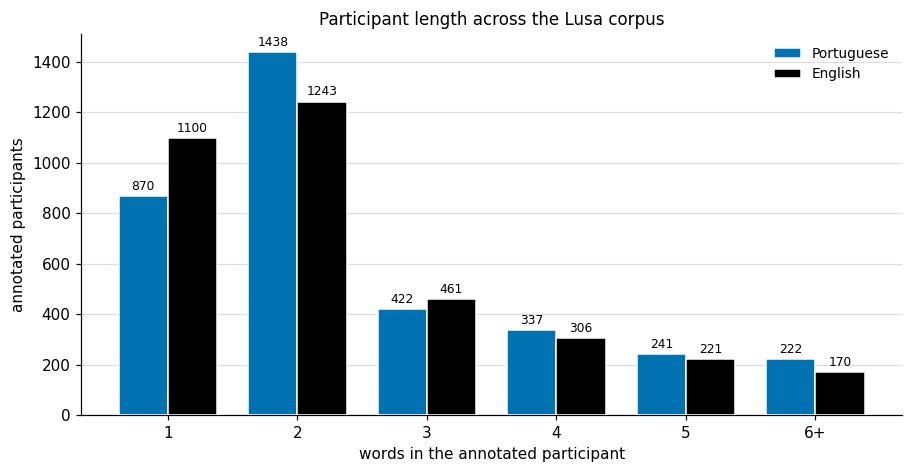

In [50]:
fig, ax = plt.subplots(figsize=(8.4, 4.4))

x = np.arange(len(length_table))
width = 0.38
for offset, language in zip([-width / 2, width / 2], c.LANGUAGE_ORDER):
    bars = ax.bar(x + offset, length_table[language], width,
                  label=language.capitalize(), color=c.LANGUAGE_COLORS[language],
                  edgecolor=SURFACE, linewidth=1.0, zorder=3)
    ax.bar_label(bars, fmt="%d", fontsize=8, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(length_table.index)
ax.set_xlabel("words in the annotated participant")
ax.set_ylabel("annotated participants")
ax.set_title("Participant length across the Lusa corpus", fontsize=11)
ax.legend(frameon=False, fontsize=9)
c.style_axis(ax)

c.save_fig(fig, "09_participant_length_distribution")
plt.show()

---

# Section A - Document-level test results

Every model at the best (template, temperature) configuration selected for it in
notebook 01, pooled. Pooling across models is deliberate: the question here is a
property of *the method* - where prompted extraction cuts a participant - not a
model leaderboard.

In [51]:
best_configs = c.load_best_configs()

test_tokens = pd.concat(
    [c.filter_to_best_configs(c.load_detailed_token("test", language), best_configs)
     for language in c.LANGUAGE_ORDER],
    ignore_index=True,
)
test_tokens = add_positions(test_tokens)
check_replay(test_tokens, "test / best configs")

print()
print(test_tokens.groupby("language")["model"].nunique().rename("models pooled"))

c:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\notebooks\results\.\_common.py:247: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


test / best configs                rows= 104720  unrecovered=   0 ( 0.00%)  verdict agreement=100.0000%

language
english       9
portuguese    9
Name: models pooled, dtype: int64


In [52]:
# Rows whose prediction matched no annotation above the scorer's threshold have no
# annotation to take a position in (`ann_len == 0`); they are all fp by construction
# and drop out of every per-slot view below.
unmatched = test_tokens["ann_len"].eq(0)
print(f"words with no matched annotation: {unmatched.sum()} "
      f"({unmatched.mean():.1%}) -- verdicts: "
      f"{test_tokens.loc[unmatched, 'result'].value_counts().to_dict()}")

coverage = (test_tokens[~unmatched]
            .groupby(["language", "ann_len"]).size()
            .unstack("language").fillna(0).astype(int))
print("\nWords booked, by annotation length:")
display(coverage.head(8))

words with no matched annotation: 19426 (18.6%) -- verdicts: {'fp': 19426}

Words booked, by annotation length:


language,english,portuguese
ann_len,,
1,3754,2824
2,12501,12760
3,7034,6447
4,6406,7374
5,5174,5813
6,2589,2901
7,1829,2814
8,768,1577


### A.0 - Which participant lengths carry the inexact matches?

The two sections that follow look only at two- and three-word participants, so the
first question is where the *errors* actually sit. The chart below is a Pareto over
annotation length restricted to the participants the models did **not** recover
exactly: bars are each length's share of all partially matched participants, ranked
from largest, and the line is the running cumulative share. Both are percentages of
the same total, so they share one axis.

Three things to read carefully:

* The unit is **annotated participants** - one per scored (prediction -> annotation)
  pairing, pooled over models - not words booked. A five-word participant counts
  once here, exactly as a one-word participant does, so this view weighs long and
  short participants equally where the earlier word-unit view did not.
* A participant is **inexact** when its pairing books at least one `fn` (an
  annotation word the model did not produce) or at least one `fp` (a word the model
  added). Pairings whose words are all `tp` are excluded, and so are predictions that
  aligned to no annotation at all - those are spurious spans, not any participant's
  boundary error.
* Buckets are ranked by their **pooled** share so that a given bar position means the
  same length in both languages. Within a single language the bars are therefore
  near-monotonic rather than strictly descending - where PT and EN disagree on the
  ranking, one of them steps up slightly.

**What this view cannot show.** The word-level file holds one row per predicted span,
so an annotated participant that *no* prediction ever aligned to leaves no row at all
and cannot appear here. `inexact` therefore means **partially matched, or matched
with no word in common** - not *never proposed*. The cell below prints how many
annotated participants of the test documents are absent for that reason, and the
strict-versus-relaxed accounting earlier in the notebook is what covers the outright
misses.

In [53]:
# Lengths above this fold into one bucket. Set high enough that the folded bucket
# stays small and ranks at the tail -- with a low cap it aggregates enough
# participants to outrank a shorter length and lands mid-axis, which reads as an error.
MAX_ANN_LEN = 10

pairings = pairing_flags(test_tokens)
# Length is taken from the annotation text with the evaluator's own tokenizer rather
# than from the replayed `ann_len`, so a bucket never depends on the replay.
pairings["ann_len"] = [len(tokenize(text)) for text in pairings["matched_annotation"]]

inexact = pairings[~pairings["exact"]].copy()

print(f"scored participant pairings : {len(pairings):>6}")
print(f"  exact word-level match    : {int(pairings['exact'].sum()):>6} "
      f"({pairings['exact'].mean():.1%})")
print(f"  inexact (FN and/or FP)    : {len(inexact):>6} "
      f"({1 - pairings['exact'].mean():.1%})   <- the population from here on")
print(f"    of which share no word with the annotation: "
      f"{int((~inexact['has_tp']).sum())}")

# The token rows behind those pairings, reused by every slot figure and table below.
test_inexact = inexact_only(test_tokens)
print(f"\nword rows: {len(test_tokens)} scored -> {len(test_inexact)} "
      f"in partially matched participants")

# The blind spot, quantified over the documents this view actually covers --
# annotations in the prompt-selection documents are not missing evidence here, they
# were simply never in scope.
test_docs = set(zip(pairings["language"], pairings["doc_id"]))
corpus_keys = {
    (language, doc_id, text)
    for language, doc_id, text in participants[["language", "doc_id", "text"]].to_numpy()
    if (language, doc_id) in test_docs
}
aligned_keys = set(zip(pairings["language"], pairings["doc_id"],
                       pairings["matched_annotation"]))
print(f"\nannotated participants in these documents that no prediction ever aligned "
      f"to,\nand which therefore cannot appear below: "
      f"{len(corpus_keys - aligned_keys)} of {len(corpus_keys)} distinct annotations")

counts = (inexact.assign(bucket=inexact["ann_len"].clip(upper=MAX_ANN_LEN).astype(int))
          .groupby(["language", "bucket"]).size()
          .unstack("language").fillna(0).astype(int)[c.LANGUAGE_ORDER])
share = counts / counts.sum()

# A Pareto ranks by magnitude, so the buckets are ordered by their *pooled* share.
# Ranking each language separately would put a different length under the same bar
# position in each series and make the two halves incomparable.
order = (counts.sum(axis=1) / counts.to_numpy().sum()).sort_values(ascending=False).index
counts, share = counts.loc[order], share.loc[order]
cumulative = share.cumsum()
labels = [f"{b}+" if b == MAX_ANN_LEN else str(b) for b in order]

summary = pd.DataFrame({
    "inexact (PT)": counts["portuguese"], "share (PT)": share["portuguese"].round(3),
    "cum. (PT)": cumulative["portuguese"].round(3),
    "inexact (EN)": counts["english"], "share (EN)": share["english"].round(3),
    "cum. (EN)": cumulative["english"].round(3),
})
summary.index = labels
summary.index.name = "annotation length"
display(summary)

for language in c.LANGUAGE_ORDER:
    covered = share.loc[[2, 3], language].sum()
    print(f"{language:<11} two- and three-word participants carry {covered:.1%} "
          f"of all partially matched participants")

scored participant pairings :  26899
  exact word-level match    :  13524 (50.3%)
  inexact (FN and/or FP)    :  13375 (49.7%)   <- the population from here on
    of which share no word with the annotation: 559

word rows: 104720 scored -> 51807 in partially matched participants

annotated participants in these documents that no prediction ever aligned to,
and which therefore cannot appear below: 752 of 5160 distinct annotations


,inexact (PT),share (PT),cum. (PT),inexact (EN),share (EN),cum. (EN)
annotation length,,,,,,
2,2563,0.377,0.377,2524,0.383,0.383
3,967,0.142,0.520,1098,0.167,0.550
4,1091,0.161,0.681,867,0.132,0.682
1,571,0.084,0.765,890,0.135,0.817
5,666,0.098,0.863,585,0.089,0.906
6,328,0.048,0.911,290,0.044,0.950
7,294,0.043,0.954,186,0.028,0.978
8,152,0.022,0.977,83,0.013,0.991
10+,84,0.012,0.989,37,0.006,0.996


portuguese  two- and three-word participants carry 52.0% of all partially matched participants
english     two- and three-word participants carry 55.0% of all partially matched participants


Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_ann_len_pareto_test.pdf


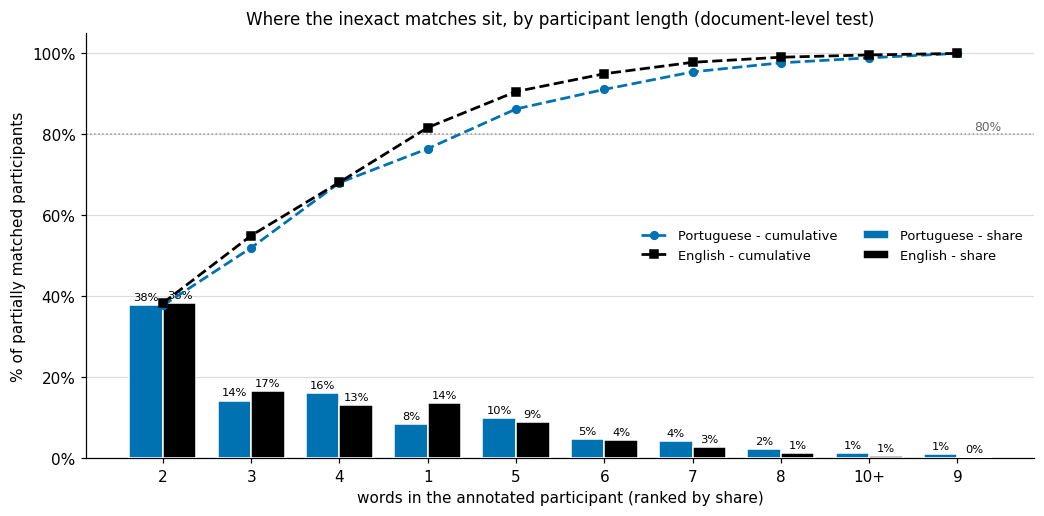

In [54]:
fig, ax = plt.subplots(figsize=(9.6, 4.8))

x = np.arange(len(order))
width = 0.38
for offset, language in zip([-width / 2, width / 2], c.LANGUAGE_ORDER):
    bars = ax.bar(x + offset, share[language] * 100, width,
                  label=f"{language.capitalize()} - share",
                  color=c.LANGUAGE_COLORS[language], edgecolor=SURFACE,
                  linewidth=1.0, zorder=3)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=7.5, padding=2)

# Cumulative on the same percentage axis -- a Pareto needs no second y-scale.
for language, marker in zip(c.LANGUAGE_ORDER, ["o", "s"]):
    ax.plot(x, cumulative[language] * 100, marker=marker, markersize=5,
            linewidth=1.8, linestyle="--", color=c.LANGUAGE_COLORS[language],
            label=f"{language.capitalize()} - cumulative", zorder=4)

ax.axhline(80, color="#999999", linewidth=1.0, linestyle=":", zorder=2)
ax.text(len(order) - 0.5, 81, "80%", fontsize=8, color="#666666", ha="right")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("words in the annotated participant (ranked by share)")
ax.set_ylabel("% of partially matched participants")
ax.set_ylim(0, 105)
ax.set_yticks(range(0, 101, 20))
ax.set_yticklabels([f"{v}%" for v in range(0, 101, 20)])
ax.set_title("Where the inexact matches sit, by participant length "
             "(document-level test)", fontsize=11)
ax.legend(frameon=False, fontsize=8.5, ncol=2, loc="center right")
c.style_axis(ax)

c.save_fig(fig, "09_ann_len_pareto_test")
plt.show()

### A.0b - Worked examples

Ten sampled cases per annotation length, showing what the alignment actually books.
One row is one **scored prediction**: the annotation it was matched against, the
prediction itself, and the words charged to each verdict. `TP` and `FN` words are read
off the annotation in slot order; `FP` words come from the prediction.

Sampling is uniform over distinct scored predictions at that length, with a fixed seed,
so the mix of clean and broken cases below is representative rather than curated - most
notably, a row with an empty `FP` **and** an empty `FN` is an exact word-level match.
`model` and `doc_id` are dropped for width; they are columns of `examples` if a case
needs tracing back.

In [55]:
SAMPLE_LENGTHS = (2, 3, 4, 5)
SAMPLE_N = 10
SAMPLE_SEED = 20260830
GROUP_KEYS = ["model", "doc_id", "template", "complete_prediction", "matched_annotation"]


def worked_examples(df, lengths=SAMPLE_LENGTHS):
    """One row per scored prediction, with the words booked to each verdict."""
    scored = df[df["ann_len"].isin(lengths)].copy()
    scored["gid"] = scored.groupby(GROUP_KEYS, sort=False).ngroup()

    # Words in slot order, so a multi-word verdict reads left to right as it appears
    # in the participant. FP words carry their anchored slot, hence the same sort.
    booked = (scored.sort_values(["gid", "ann_pos"])
              .groupby(["gid", "result"])["token"]
              .apply(lambda words: " ".join(words.astype(str)))
              .unstack("result").reindex(columns=OUTCOME_ORDER).fillna(""))

    meta = scored.drop_duplicates("gid").set_index("gid")[GROUP_KEYS + ["ann_len"]]
    table = meta.join(booked)
    table["pred"] = [" ".join(ast.literal_eval(p)) for p in table["complete_prediction"]]
    return (table.rename(columns={"matched_annotation": "ann", "tp": "TP",
                                  "fp": "FP", "fn": "FN"})
            [["ann_len", "ann", "pred", "TP", "FP", "FN", "model", "doc_id"]]
            .reset_index(drop=True))


examples = worked_examples(test_tokens)

sample = pd.concat([
    examples[examples["ann_len"] == length]
    .sample(min(SAMPLE_N, int((examples["ann_len"] == length).sum())),
            random_state=SAMPLE_SEED)
    for length in SAMPLE_LENGTHS
])

with pd.option_context("display.max_colwidth", 60, "display.max_rows", 60):
    display(sample[["ann_len", "ann", "pred", "TP", "FP", "FN"]]
            .reset_index(drop=True))

exact = (sample["FP"] == "") & (sample["FN"] == "")
print(f"{int(exact.sum())} of the {len(sample)} sampled cases are exact word-level "
      f"matches; {int((~exact).sum())} book at least one FP or FN")

,ann_len,ann,pred,TP,FP,FN
0,2,Guiné Bissau,guiné bissau,guiné bissau,,
1,2,a VMER,a vmer,a vmer,,
2,2,785 kilos,785 kilos,785 kilos,,
3,2,the vessel,vessel,vessel,,the
4,2,Judiciary Police,the judiciary police,judiciary police,the,
5,2,Juarce Martins,juarce martins,juarce martins,,
6,2,a Alemanha,atentado na alemanha,alemanha,atentado na,a
7,2,a man,man,man,,a
8,2,the well,a well,well,a,the
9,2,his father,father,father father,,his his


11 of the 40 sampled cases are exact word-level matches; 29 book at least one FP or FN


### A.1 - Two-word participants

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len2_test.pdf


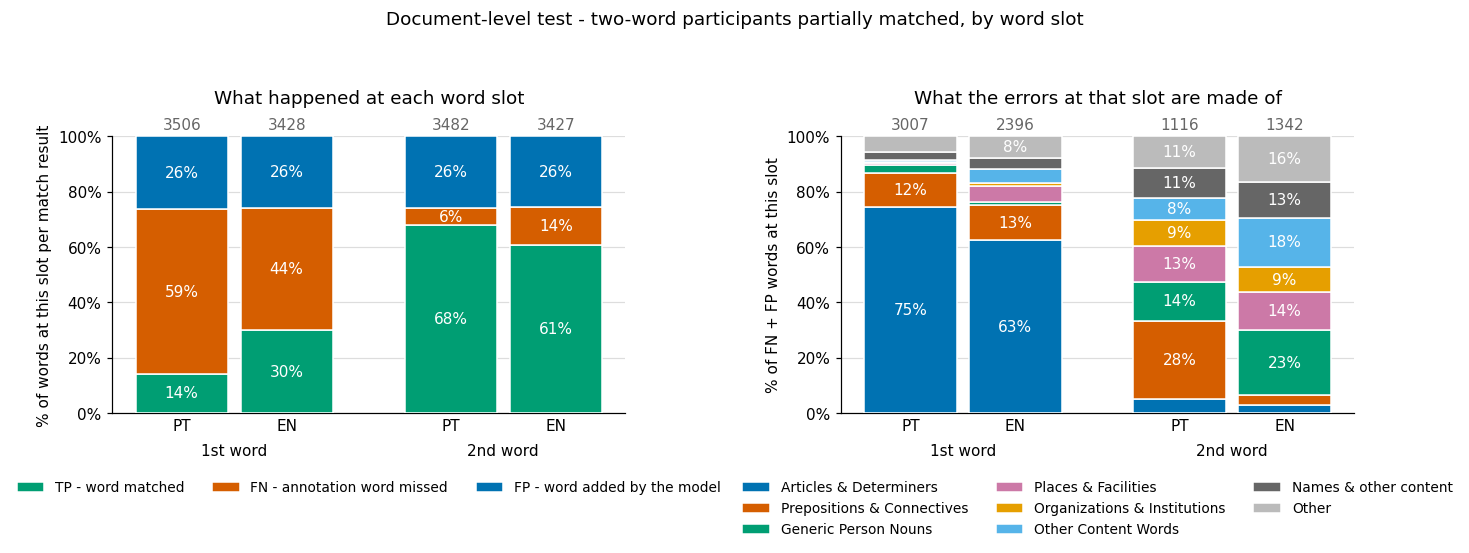

In [56]:
position_figure(
    test_inexact, ann_len=2, group_col="language", groups=c.LANGUAGE_ORDER,
    title="Document-level test - two-word participants partially matched, by word slot",
    filename="09_word_position_len2_test",
)

### A.2 - Three-word participants

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len3_test.pdf


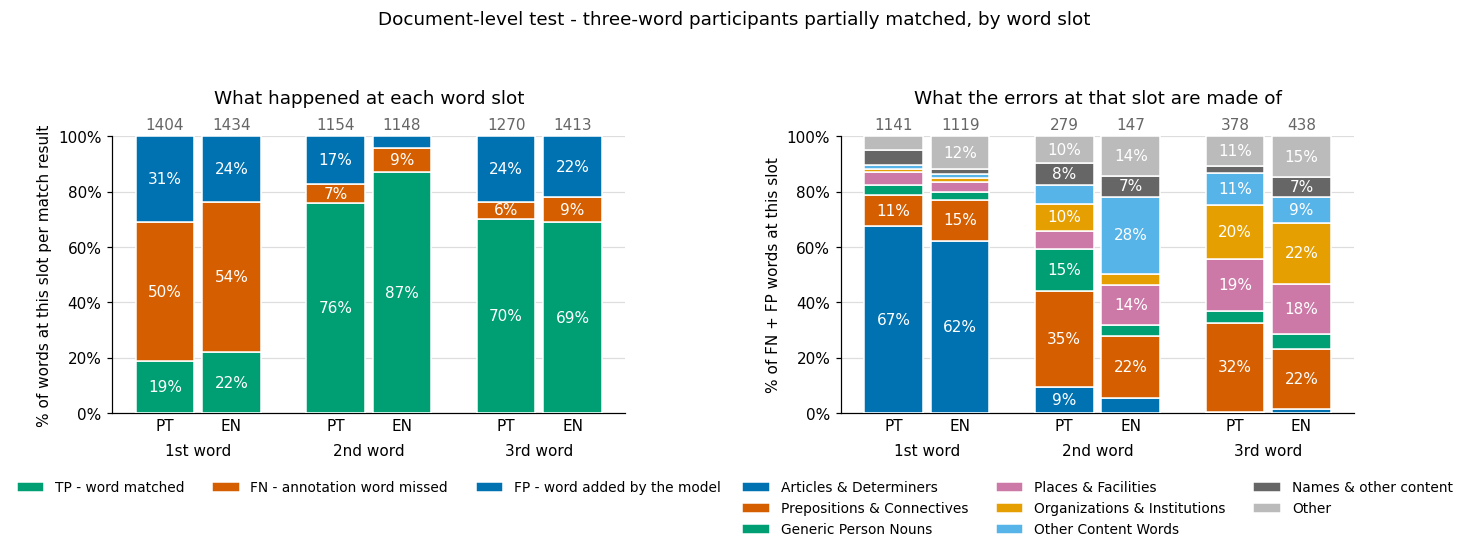

In [57]:
position_figure(
    test_inexact, ann_len=3, group_col="language", groups=c.LANGUAGE_ORDER,
    title="Document-level test - three-word participants partially matched, by word slot",
    filename="09_word_position_len3_test",
)

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len4_test.pdf


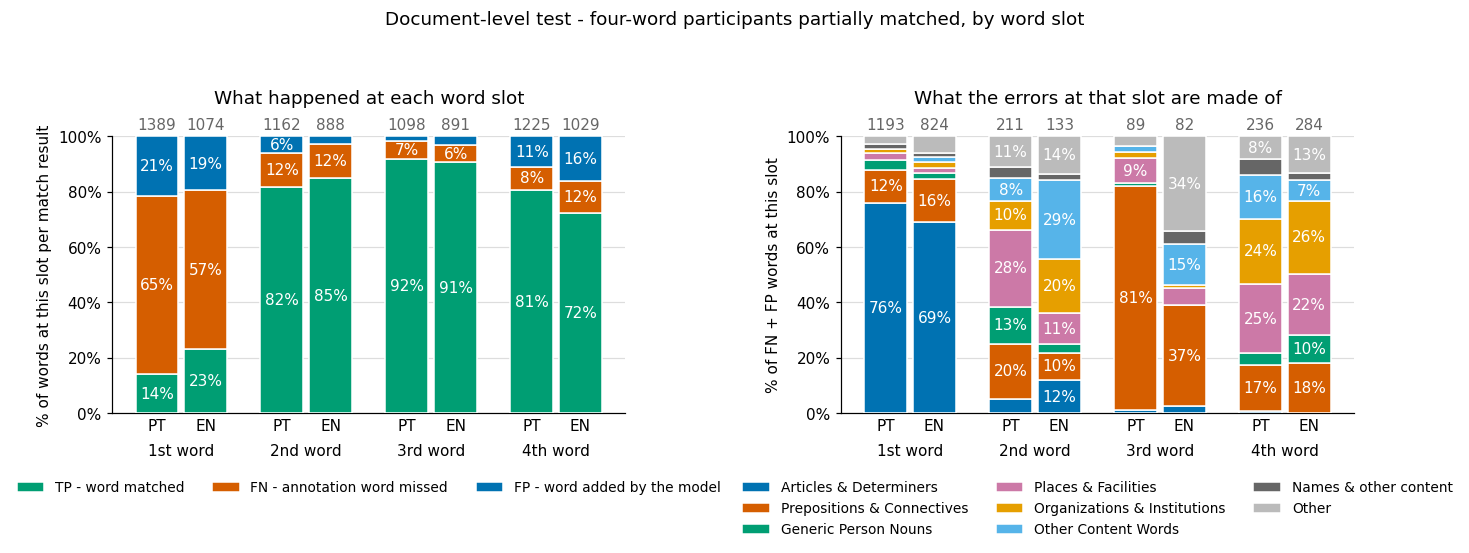

In [58]:
position_figure(
    test_inexact, ann_len=4, group_col="language", groups=c.LANGUAGE_ORDER,
    title="Document-level test - four-word participants partially matched, by word slot",
    filename="09_word_position_len4_test",
)

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len5_test.pdf


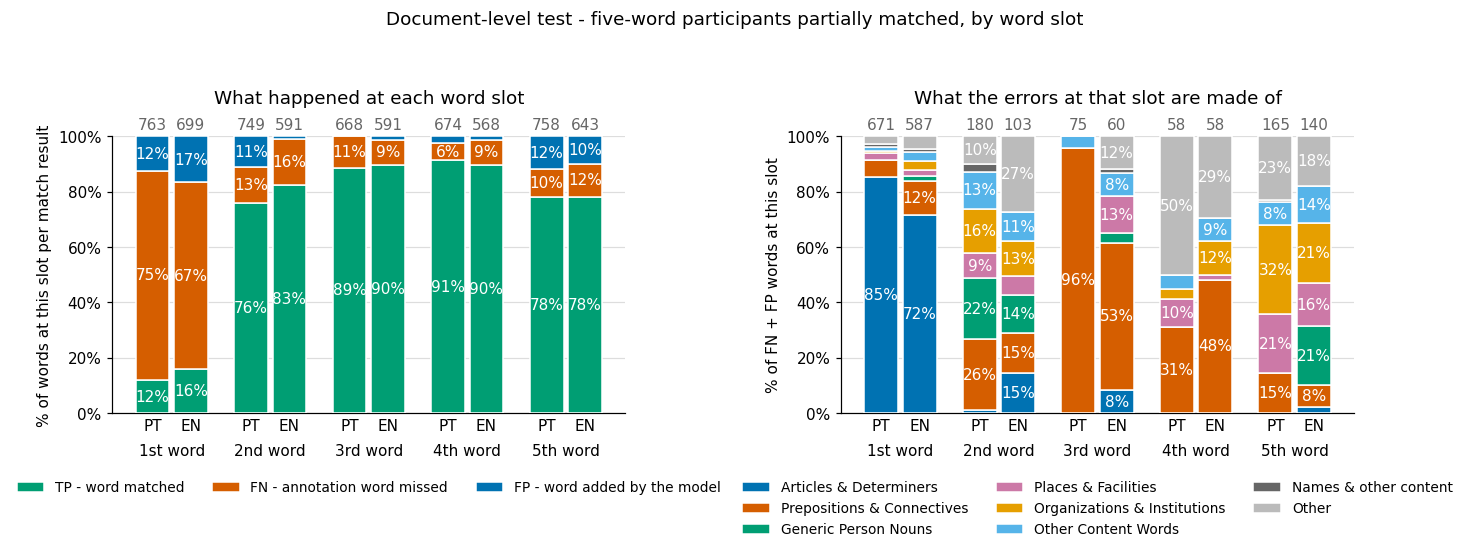

In [59]:
position_figure(
    test_inexact, ann_len=5, group_col="language", groups=c.LANGUAGE_ORDER,
    title="Document-level test - five-word participants partially matched, by word slot",
    filename="09_word_position_len5_test",
)

In [60]:
def slot_table(df, ann_len):
    """The numbers behind the left panel, for quoting into the report."""
    sub = df[df["ann_len"] == ann_len]
    counts = (sub.groupby(["language", "ann_pos", "result"]).size()
              .unstack("result").reindex(columns=OUTCOME_ORDER).fillna(0).astype(int))
    counts["total"] = counts.sum(axis=1)
    shares = counts[OUTCOME_ORDER].div(counts["total"], axis=0)
    return counts.join(shares.round(3), rsuffix="_share")


def error_category_table(df, ann_len):
    """The numbers behind the right panel: the lexical make-up of FN + FP words."""
    sub = df[(df["ann_len"] == ann_len) & (df["result"].isin(["fn", "fp"]))]
    counts = (sub.groupby(["language", "ann_pos", "category"]).size()
              .unstack("category").fillna(0).astype(int))
    shares = counts.div(counts.sum(axis=1), axis=0)
    return shares.round(3)


for ann_len in (2, 3):
    print(f"--- {ann_len}-word participants: verdict mix per slot ---")
    display(slot_table(test_inexact, ann_len))
    print(f"--- {ann_len}-word participants: lexical make-up of FN + FP per slot ---")
    display(error_category_table(test_inexact, ann_len))

--- 2-word participants: verdict mix per slot ---


result                tp    fn   fp  total  tp_share  fn_share  fp_share
language   ann_pos                                                      
english    1        1032  1512  884   3428     0.301     0.441     0.258
           2        2085   465  877   3427     0.608     0.136     0.256
portuguese 1         499  2084  923   3506     0.142     0.594     0.263
           2        2366   217  899   3482     0.679     0.062     0.258

--- 2-word participants: lexical make-up of FN + FP per slot ---


category            Articles & Determiners  Generic Person Nouns  Names & other content  Numbers & Quantities  Objects & Substances  Organizations & Institutions  Other Content Words  Person Names  \
language   ann_pos                                                                                                                                                                                     
english    1                         0.626                 0.012                  0.041                 0.043                 0.003                         0.013                0.048         0.000   
           2                         0.031                 0.233                  0.129                 0.039                 0.092                         0.092                0.177         0.032   
portuguese 1                         0.746                 0.027                  0.028                 0.043                 0.007                         0.004                0.006         0.001   
           2                         0.049                 0.140                  0.109                 0.031                 0.076                         0.093                0.078         0.000   

category            Places & Facilities  Prepositions & Connectives  Pronouns  
language   ann_pos                                                             
english    1                      0.056                       0.126     0.030  
           2                      0.137                       0.036     0.001  
portuguese 1                      0.010                       0.123     0.005  
           2                      0.132                       0.285     0.006

--- 3-word participants: verdict mix per slot ---


result                tp   fn   fp  total  tp_share  fn_share  fp_share
language   ann_pos                                                     
english    1         315  781  338   1434     0.220     0.545     0.236
           2        1001  101   46   1148     0.872     0.088     0.040
           3         975  127  311   1413     0.690     0.090     0.220
portuguese 1         263  706  435   1404     0.187     0.503     0.310
           2         875   82  197   1154     0.758     0.071     0.171
           3         892   78  300   1270     0.702     0.061     0.236

--- 3-word participants: lexical make-up of FN + FP per slot ---


category            Articles & Determiners  Generic Person Nouns  Names & other content  Numbers & Quantities  Objects & Substances  Organizations & Institutions  Other Content Words  Person Names  \
language   ann_pos                                                                                                                                                                                     
english    1                         0.624                 0.029                  0.018                 0.064                 0.001                         0.013                0.016         0.000   
           2                         0.054                 0.041                  0.075                 0.048                 0.000                         0.041                0.279         0.054   
           3                         0.014                 0.053                  0.073                 0.032                 0.080                         0.219                0.094         0.014   
portuguese 1                         0.675                 0.036                  0.055                 0.020                 0.021                         0.011                0.013         0.004   
           2                         0.093                 0.154                  0.079                 0.018                 0.043                         0.097                0.068         0.036   
           3                         0.005                 0.045                  0.026                 0.021                 0.053                         0.196                0.114         0.032   

category            Places & Facilities  Prepositions & Connectives  Pronouns  
language   ann_pos                                                             
english    1                      0.038                       0.147     0.052  
           2                      0.143                       0.224     0.041  
           3                      0.183                       0.219     0.021  
portuguese 1                      0.046                       0.114     0.004  
           2                      0.065                       0.348     0.000  
           3                      0.188                       0.320     0.000

---

# Section B - Sentence-level results

`qwen3_14b` at *T*=0.3 over the same test documents, scored by the same code after the
per-sentence answers are folded back into the document-level answer format. Read from
`results/sentence_level/ext/`, the span-extraction output, so the word slots reflect the
extraction stage alone and not any span the later classification stage dropped.

The two prompt conditions are kept apart rather than pooled - `sent_def_exp` adds the
participant definition to all three stages, which is precisely the kind of lever that
could move where a span is cut.

In [61]:
SENTENCE_CONDITIONS = {"sent_exp": "ext_exp", "sent_def_exp": "ext_def_exp"}
SENTENCE_DIR = c.RESULTS_DIR / "sentence_level" / "ext"

frames = []
for language in c.LANGUAGE_ORDER:
    frame = pd.read_csv(SENTENCE_DIR / language / "detailed_results_token_level.csv")
    frame = frame.rename(columns={"modelo": "model"})
    frame["language"] = language
    frame["stage"] = "sentence_level"
    base = frame["template"].str.split("_temp").str[0]
    frame["condition"] = base.map({v: k for k, v in SENTENCE_CONDITIONS.items()})
    frames.append(frame)

sentence_tokens = add_positions(pd.concat(frames, ignore_index=True))
check_replay(sentence_tokens, "sentence level / ext")

print()
print(sentence_tokens.groupby(["language", "condition"]).size().rename("words"))

# The partially matched participants of this section, on the same definition used for
# the document-level figures above.
sentence_inexact = inexact_only(sentence_tokens)
_flags = pairing_flags(sentence_tokens)
print()
print(f"sentence-level pairings: {len(_flags)} scored, "
      f"{int((~_flags['exact']).sum())} inexact "
      f"({1 - _flags['exact'].mean():.1%}); word rows "
      f"{len(sentence_tokens)} -> {len(sentence_inexact)}")

sentence level / ext               rows=  23383  unrecovered=   0 ( 0.00%)  verdict agreement=100.0000%

language    condition   
english     sent_def_exp    5292
            sent_exp        5935
portuguese  sent_def_exp    5933
            sent_exp        6223
Name: words, dtype: int64

sentence-level pairings: 6739 scored, 2856 inexact (42.4%); word rows 23383 -> 11435


### B.1 - two-word participants partially matched

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len2_sentence_sent_exp.pdf


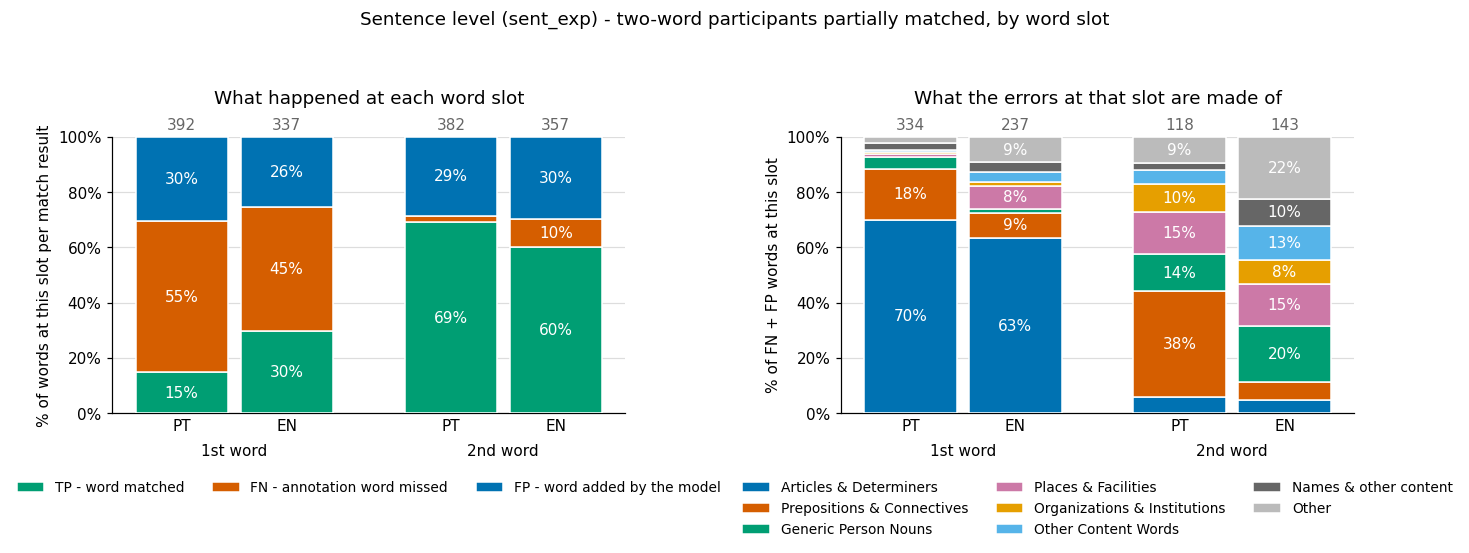

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len2_sentence_sent_def_exp.pdf


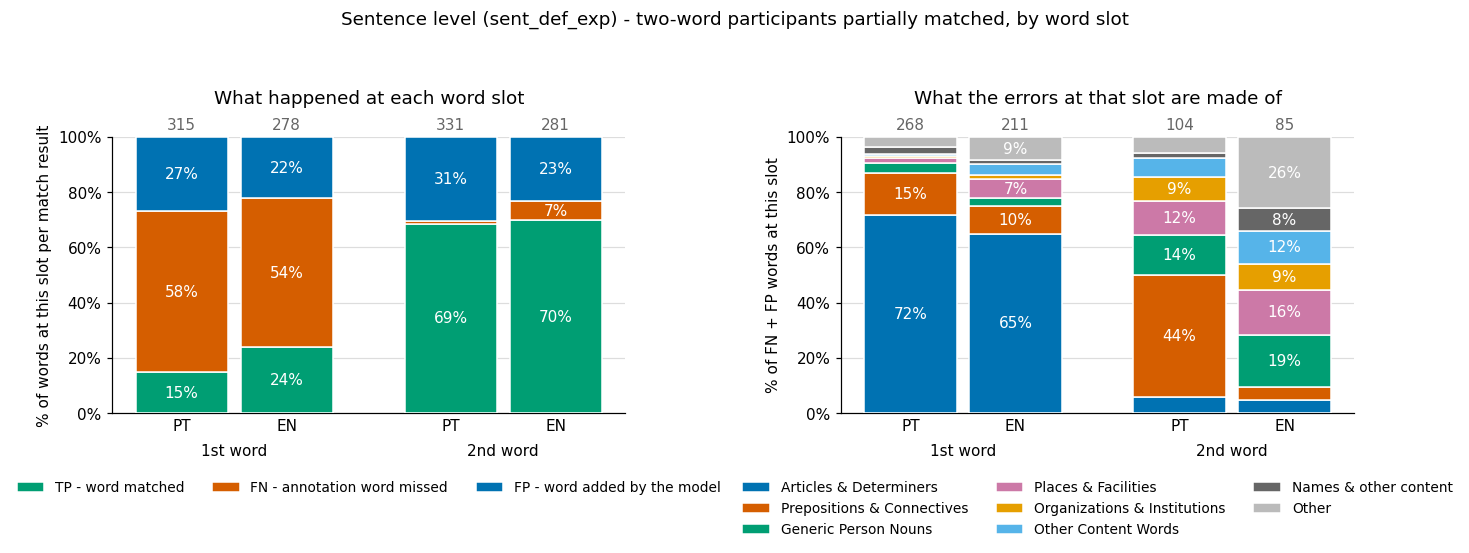

In [62]:
for condition in SENTENCE_CONDITIONS:
    position_figure(
        sentence_inexact[sentence_inexact["condition"] == condition],
        ann_len=2, group_col="language", groups=c.LANGUAGE_ORDER,
        title=f"Sentence level ({condition}) - two-word participants partially matched, by word slot",
        filename=f"09_word_position_len2_sentence_{condition}",
    )

### B.2 - Three-word participants

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len3_sentence_sent_exp.pdf


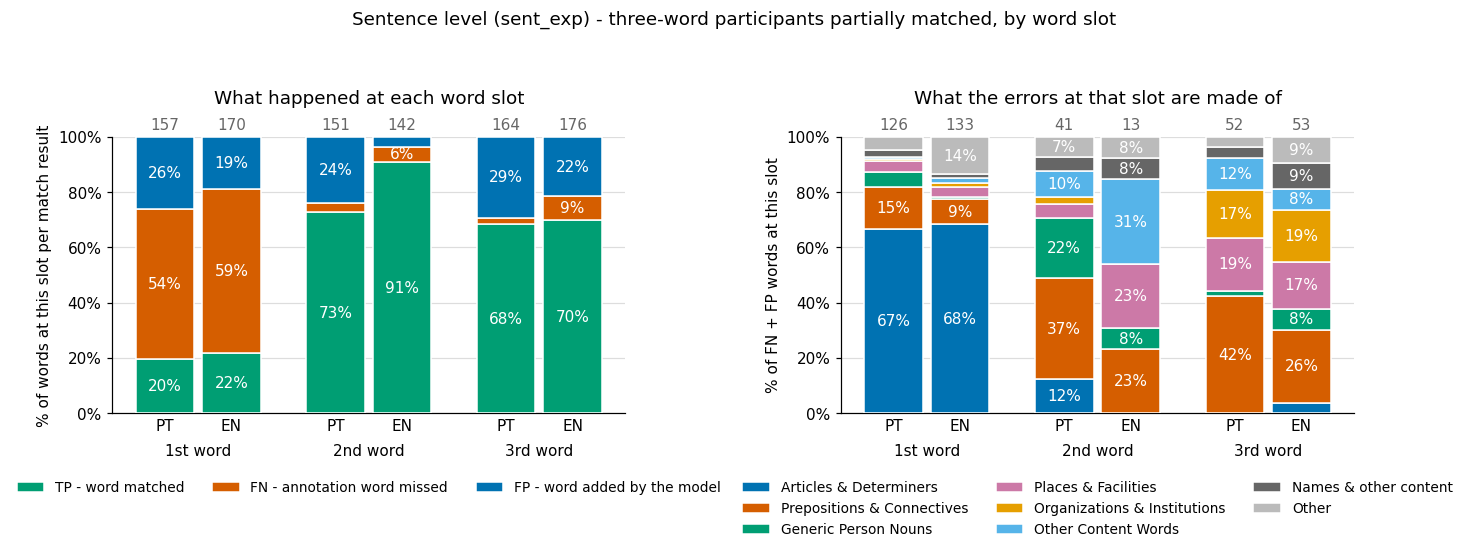

Saved C:\Users\davib\Desktop\MSc_DataScience\thesis\gpt_struct_me\report\Figures\results\09_word_position_len3_sentence_sent_def_exp.pdf


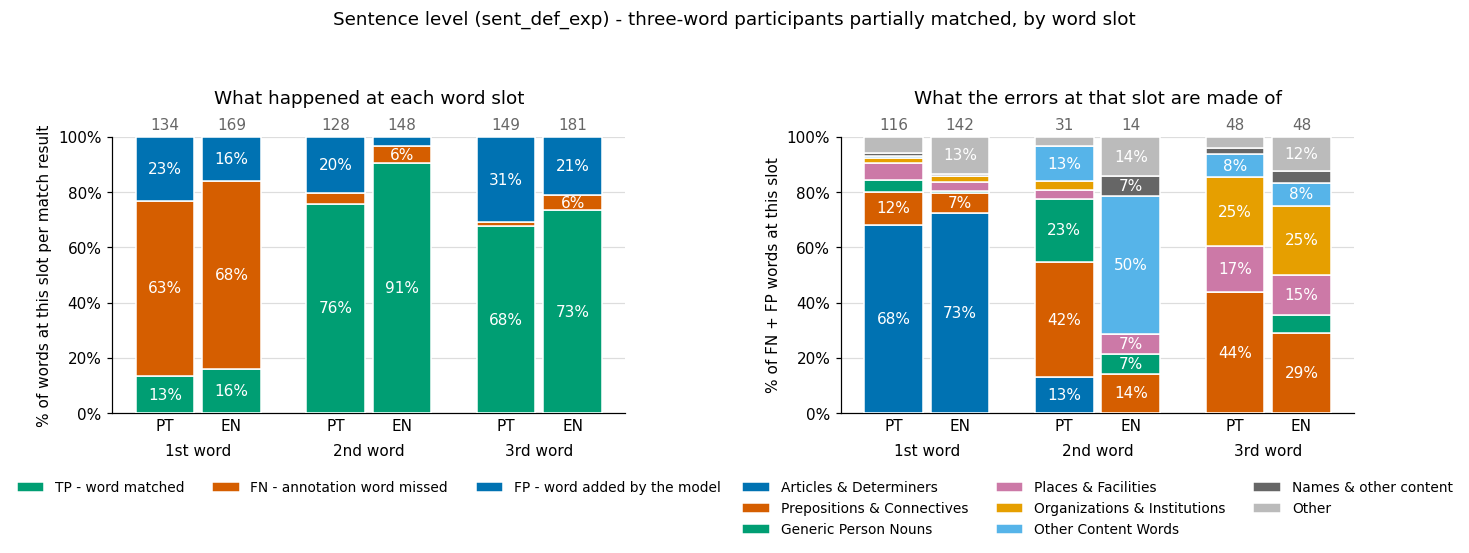

In [63]:
for condition in SENTENCE_CONDITIONS:
    position_figure(
        sentence_inexact[sentence_inexact["condition"] == condition],
        ann_len=3, group_col="language", groups=c.LANGUAGE_ORDER,
        title=f"Sentence level ({condition}) - three-word participants partially matched, by word slot",
        filename=f"09_word_position_len3_sentence_{condition}",
    )

In [64]:
for condition in SENTENCE_CONDITIONS:
    for ann_len in (2, 3):
        sub = sentence_inexact[sentence_inexact["condition"] == condition]
        print(f"--- {condition}, {ann_len}-word participants: verdict mix per slot ---")
        display(slot_table(sub, ann_len))
        print(f"--- {condition}, {ann_len}-word participants: FN + FP make-up ---")
        display(error_category_table(sub, ann_len))

--- sent_exp, 2-word participants: verdict mix per slot ---


result               tp   fn   fp  total  tp_share  fn_share  fp_share
language   ann_pos                                                    
english    1        100  151   86    337     0.297     0.448     0.255
           2        214   37  106    357     0.599     0.104     0.297
portuguese 1         58  215  119    392     0.148     0.548     0.304
           2        264    9  109    382     0.691     0.024     0.285

--- sent_exp, 2-word participants: FN + FP make-up ---


category            Articles & Determiners  Generic Person Nouns  Names & other content  Numbers & Quantities  Objects & Substances  Organizations & Institutions  Other Content Words  Person Names  \
language   ann_pos                                                                                                                                                                                     
english    1                         0.633                 0.013                  0.034                 0.046                 0.000                         0.013                0.038         0.000   
           2                         0.049                 0.203                  0.098                 0.063                 0.119                         0.084                0.126         0.042   
portuguese 1                         0.701                 0.045                  0.024                 0.012                 0.006                         0.009                0.006         0.000   
           2                         0.059                 0.136                  0.025                 0.025                 0.059                         0.102                0.051         0.000   

category            Places & Facilities  Prepositions & Connectives  Pronouns  
language   ann_pos                                                             
english    1                      0.084                       0.093     0.046  
           2                      0.154                       0.063     0.000  
portuguese 1                      0.009                       0.183     0.006  
           2                      0.153                       0.381     0.008

--- sent_exp, 3-word participants: verdict mix per slot ---


result               tp   fn  fp  total  tp_share  fn_share  fp_share
language   ann_pos                                                   
english    1         37  101  32    170     0.218     0.594     0.188
           2        129    8   5    142     0.908     0.056     0.035
           3        123   15  38    176     0.699     0.085     0.216
portuguese 1         31   85  41    157     0.197     0.541     0.261
           2        110    5  36    151     0.728     0.033     0.238
           3        112    4  48    164     0.683     0.024     0.293

... (6 outputs left out)

--- sent_def_exp, 3-word participants: verdict mix per slot ---


result               tp   fn  fp  total  tp_share  fn_share  fp_share
language   ann_pos                                                   
english    1         27  115  27    169     0.160     0.680     0.160
           2        134    9   5    148     0.905     0.061     0.034
           3        133   10  38    181     0.735     0.055     0.210
portuguese 1         18   85  31    134     0.134     0.634     0.231
           2         97    5  26    128     0.758     0.039     0.203
           3        101    2  46    149     0.678     0.013     0.309

--- sent_def_exp, 3-word participants: FN + FP make-up ---


category            Articles & Determiners  Generic Person Nouns  Names & other content  Numbers & Quantities  Objects & Substances  Organizations & Institutions  Other Content Words  Person Names  \
language   ann_pos                                                                                                                                                                                     
english    1                         0.725                 0.007                  0.007                 0.056                 0.000                         0.021                0.000         0.000   
           2                         0.000                 0.071                  0.071                 0.000                 0.000                         0.000                0.500         0.071   
           3                         0.000                 0.062                  0.042                 0.000                 0.062                         0.250                0.083         0.000   
portuguese 1                         0.681                 0.043                  0.009                 0.026                 0.026                         0.017                0.009         0.000   
           2                         0.129                 0.226                  0.000                 0.000                 0.000                         0.032                0.129         0.032   
           3                         0.000                 0.000                  0.021                 0.000                 0.021                         0.250                0.083         0.021   

category            Places & Facilities  Prepositions & Connectives  Pronouns  
language   ann_pos                                                             
english    1                      0.035                       0.070     0.077  
           2                      0.071                       0.143     0.071  
           3                      0.146                       0.292     0.062  
portuguese 1                      0.060                       0.121     0.009  
           2                      0.032                       0.419     0.000  
           3                      0.167                       0.438     0.000